# Análise Exploratória de Dados - Previsão de Atrasos em Voos
## Projeto de Machine Learning aplicado a dados de aviação

---

## Índice
1. [Configuração do Ambiente](#1-configuracao)
2. [Carregamento dos Dados](#2-carregamento)
3. [Entendimento Inicial](#3-entendimento)
4. [Análise Descritiva](#4-analise-descritiva)
5. [Tratamento de Valores Ausentes](#5-valores-ausentes)
6. [Engenharia de Features](#6-features)
7. [Visualizações e Insights](#7-visualizacoes)
8. [Conclusões](#8-conclusoes)

---

## 1. Configuração do Ambiente <a id='1-configuracao'></a>

### 1.1 Importação de Bibliotecas

Nesta seção, importamos todas as bibliotecas Python necessárias para nossa análise exploratória de dados (EDA).

**Bibliotecas principais:**
- **pandas**: Manipulação e análise de dados tabulares
- **numpy**: Operações matemáticas e arrays multidimensionais
- **matplotlib/seaborn/plotly**: Visualização de dados (gráficos estáticos e interativos)
- **datetime**: Manipulação de datas e horários

**Por que configurar no início?**
Centralizar todas as importações facilita:
- Identificar dependências do projeto
- Resolver problemas de instalação de pacotes
- Reproduzir o ambiente em outras máquinas

In [1]:
# Manipulação de dados
import pandas as pd
import numpy as np

# Visualização de dados
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Utilitários
from datetime import datetime
import warnings
from tqdm import tqdm

# Configurações
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)  # Mostrar todas as colunas
pd.set_option('display.max_rows', 100)       # Mostrar até 100 linhas
pd.set_option('display.float_format', '{:.2f}'.format)  # 2 casas decimais

# Configuração de gráficos
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print("Bibliotecas importadas com sucesso!")
print(f"Versão Pandas: {pd.__version__}")
print(f"Versão NumPy: {np.__version__}")

Bibliotecas importadas com sucesso!
Versão Pandas: 2.1.4
Versão NumPy: 1.26.2


### 1.2 Definição de Caminhos e Constantes

Definimos os caminhos dos arquivos e constantes que usaremos ao longo da análise.

In [2]:
# Caminhos dos arquivos de dados
DATA_PATH = '../data/raw/'  # Pasta onde estão os CSVs originais
FLIGHTS_FILE = f'{DATA_PATH}flights.csv'
AIRPORTS_FILE = f'{DATA_PATH}airports.csv'
AIRLINES_FILE = f'{DATA_PATH}airlines.csv'

# Caminhos para salvar resultados
PROCESSED_DATA_PATH = '../data/processed/'
REPORTS_PATH = '../reports/'
FIGURES_PATH = '../reports/figures/'

# Constantes de negócio
DELAY_THRESHOLD = 15  # Voo é considerado atrasado se atraso > 15 minutos
RANDOM_STATE = 42     # Seed para reprodutibilidade

print("Caminhos e constantes definidos!")
print(f"Arquivo de voos: {FLIGHTS_FILE}")
print(f"Arquivo de aeroportos: {AIRPORTS_FILE}")
print(f"Arquivo de companhias: {AIRLINES_FILE}")

Caminhos e constantes definidos!
Arquivo de voos: ../data/raw/flights.csv
Arquivo de aeroportos: ../data/raw/airports.csv
Arquivo de companhias: ../data/raw/airlines.csv


---
## 2. Carregamento dos Dados <a id='2-carregamento'></a>

### 2.1 Carregamento do Dataset de Voos

O dataset `flights.csv` contém aproximadamente **5.8 milhões de registros**. 
Vamos carregar o dataset completo para análise.

In [3]:
# Carregar o dataset COMPLETO de voos (5.819.080 registros)
print("Carregando dataset COMPLETO de voos...")
print("Isso pode levar alguns minutos...\n")

# Carregar dataset completo
df_flights_sample = pd.read_csv(FLIGHTS_FILE)

print(f"Dataset completo carregado com sucesso!")
print(f"Dimensões: {df_flights_sample.shape[0]:,} linhas x {df_flights_sample.shape[1]} colunas")
print(f"Memória utilizada: {df_flights_sample.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

Carregando dataset COMPLETO de voos...
Isso pode levar alguns minutos...

Dataset completo carregado com sucesso!
Dimensões: 5,819,079 linhas x 31 colunas
Memória utilizada: 2655.75 MB


In [4]:
# Renomear para df_flights para facilitar o uso nas células seguintes
df_flights = df_flights_sample.copy()

print("Dataset preparado para análise!")
print(f"Total de registros: {len(df_flights):,}")

Dataset preparado para análise!
Total de registros: 5,819,079


### 2.2 Carregamento dos Datasets Auxiliares

In [5]:
# Carregar dataset de aeroportos
print(" Carregando dataset de aeroportos...")
df_airports = pd.read_csv(AIRPORTS_FILE)
print(f" {len(df_airports)} aeroportos carregados!\n")

# Carregar dataset de companhias aéreas
print(" Carregando dataset de companhias aéreas...")
df_airlines = pd.read_csv(AIRLINES_FILE)
print(f" {len(df_airlines)} companhias aéreas carregadas!\n")

print(" Todos os datasets carregados com sucesso!")

 Carregando dataset de aeroportos...
 322 aeroportos carregados!

 Carregando dataset de companhias aéreas...
 14 companhias aéreas carregadas!

 Todos os datasets carregados com sucesso!


### 2.3 Visualização Inicial dos Dados

Vamos dar uma olhada inicial em cada dataset para entender sua estrutura.

In [6]:
# Para o restante da análise, vamos trabalhar com a amostra
# Renomeie para df_flights para facilitar
df_flights = df_flights_sample.copy()

print("="*80)
print(" DATASET DE VOOS - Primeiras 5 linhas")
print("="*80)
display(df_flights.head())

 DATASET DE VOOS - Primeiras 5 linhas


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,DEPARTURE_TIME,DEPARTURE_DELAY,TAXI_OUT,WHEELS_OFF,SCHEDULED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,WHEELS_ON,TAXI_IN,SCHEDULED_ARRIVAL,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,2354.00,-11.00,21.00,15.00,205.00,194.00,169.00,1448,404.00,4.00,430,408.00,-22.00,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,2.00,-8.00,12.00,14.00,280.00,279.00,263.00,2330,737.00,4.00,750,741.00,-9.00,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,18.00,-2.00,16.00,34.00,286.00,293.00,266.00,2296,800.00,11.00,806,811.00,5.00,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,15.00,-5.00,15.00,30.00,285.00,281.00,258.00,2342,748.00,8.00,805,756.00,-9.00,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,24.00,-1.00,11.00,35.00,235.00,215.00,199.00,1448,254.00,5.00,320,259.00,-21.00,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
print("="*80)
print(" DATASET DE AEROPORTOS - Primeiras 5 linhas")
print("="*80)
display(df_airports.head())

 DATASET DE AEROPORTOS - Primeiras 5 linhas


,IATA_CODE,AIRPORT,CITY,STATE,COUNTRY,LATITUDE,LONGITUDE
0,ABE,Lehigh Valley International Airport,Allentown,PA,USA,40.65,-75.44
1,ABI,Abilene Regional Airport,Abilene,TX,USA,32.41,-99.68
2,ABQ,Albuquerque International Sunport,Albuquerque,NM,USA,35.04,-106.61
3,ABR,Aberdeen Regional Airport,Aberdeen,SD,USA,45.45,-98.42
4,ABY,Southwest Georgia Regional Airport,Albany,GA,USA,31.54,-84.19


In [8]:
print("="*80)
print(" DATASET DE COMPANHIAS AÉREAS - Todas as companhias")
print("="*80)
display(df_airlines)

 DATASET DE COMPANHIAS AÉREAS - Todas as companhias


,IATA_CODE,AIRLINE
0,UA,United Air Lines Inc.
1,AA,American Airlines Inc.
2,US,US Airways Inc.
3,F9,Frontier Airlines Inc.
4,B6,JetBlue Airways
5,OO,Skywest Airlines Inc.
6,AS,Alaska Airlines Inc.
7,NK,Spirit Air Lines
8,WN,Southwest Airlines Co.
9,DL,Delta Air Lines Inc.


---
## 3. Entendimento Inicial dos Dados <a id='3-entendimento'></a>

### 3.1 Estrutura dos Datasets

Vamos entender a estrutura de cada dataset: tipos de dados, quantidade de registros, etc.

In [9]:
print("="*80)
print(" INFORMAÇÕES DO DATASET DE VOOS")
print("="*80)
print(f"\n Dimensões: {df_flights.shape[0]:,} linhas x {df_flights.shape[1]} colunas\n")

print(" Tipos de dados e valores não-nulos:")
df_flights.info()

 INFORMAÇÕES DO DATASET DE VOOS

 Dimensões: 5,819,079 linhas x 31 colunas

 Tipos de dados e valores não-nulos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5819079 entries, 0 to 5819078
Data columns (total 31 columns):
 #   Column               Dtype  
---  ------               -----  
 0   YEAR                 int64  
 1   MONTH                int64  
 2   DAY                  int64  
 3   DAY_OF_WEEK          int64  
 4   AIRLINE              object 
 5   FLIGHT_NUMBER        int64  
 6   TAIL_NUMBER          object 
 7   ORIGIN_AIRPORT       object 
 8   DESTINATION_AIRPORT  object 
 9   SCHEDULED_DEPARTURE  int64  
 10  DEPARTURE_TIME       float64
 11  DEPARTURE_DELAY      float64
 12  TAXI_OUT             float64
 13  WHEELS_OFF           float64
 14  SCHEDULED_TIME       float64
 15  ELAPSED_TIME         float64
 16  AIR_TIME             float64
 17  DISTANCE             int64  
 18  WHEELS_ON            float64
 19  TAXI_IN              float64
 20  SCHEDULED_ARRIVAL    

In [10]:
print("="*80)
print(" INFORMAÇÕES DO DATASET DE AEROPORTOS")
print("="*80)
df_airports.info()

 INFORMAÇÕES DO DATASET DE AEROPORTOS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 322 entries, 0 to 321
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   IATA_CODE  322 non-null    object 
 1   AIRPORT    322 non-null    object 
 2   CITY       322 non-null    object 
 3   STATE      322 non-null    object 
 4   COUNTRY    322 non-null    object 
 5   LATITUDE   319 non-null    float64
 6   LONGITUDE  319 non-null    float64
dtypes: float64(2), object(5)
memory usage: 17.7+ KB


In [11]:
print("="*80)
print(" INFORMAÇÕES DO DATASET DE COMPANHIAS AÉREAS")
print("="*80)
df_airlines.info()

 INFORMAÇÕES DO DATASET DE COMPANHIAS AÉREAS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   IATA_CODE  14 non-null     object
 1   AIRLINE    14 non-null     object
dtypes: object(2)
memory usage: 356.0+ bytes


### 3.2 Dicionário de Dados

Vamos documentar o significado de cada coluna do dataset principal (flights).

In [12]:
# Criar dicionário de dados
data_dictionary = {
    'Coluna': df_flights.columns,
    'Tipo': df_flights.dtypes.values,
    'Não-Nulos': df_flights.count().values,
    'Nulos': df_flights.isnull().sum().values,
    '% Nulos': (df_flights.isnull().sum() / len(df_flights) * 100).values
}

df_dict = pd.DataFrame(data_dictionary)

print("="*80)
print(" DICIONÁRIO DE DADOS - Dataset de Voos")
print("="*80)
display(df_dict.style.background_gradient(subset=['% Nulos'], cmap='YlOrRd'))

 DICIONÁRIO DE DADOS - Dataset de Voos


,Coluna,Tipo,Não-Nulos,Nulos,% Nulos
0,YEAR,int64,5819079,0,0.000000
1,MONTH,int64,5819079,0,0.000000
2,DAY,int64,5819079,0,0.000000
3,DAY_OF_WEEK,int64,5819079,0,0.000000
4,AIRLINE,object,5819079,0,0.000000
5,FLIGHT_NUMBER,int64,5819079,0,0.000000
6,TAIL_NUMBER,object,5804358,14721,0.252978
7,ORIGIN_AIRPORT,object,5819079,0,0.000000
8,DESTINATION_AIRPORT,object,5819079,0,0.000000
9,SCHEDULED_DEPARTURE,int64,5819079,0,0.000000


### 3.3 Descrição Semântica das Colunas Principais

Aqui documentamos o significado de negócio de cada coluna importante:

In [13]:
# Descrição semântica das colunas
column_descriptions = {
    'YEAR': 'Ano do voo',
    'MONTH': 'Mês do voo (1-12)',
    'DAY': 'Dia do mês (1-31)',
    'DAY_OF_WEEK': 'Dia da semana (1=Segunda, 7=Domingo)',
    'AIRLINE': 'Código IATA da companhia aérea',
    'FLIGHT_NUMBER': 'Número do voo',
    'TAIL_NUMBER': 'Número de identificação da aeronave',
    'ORIGIN_AIRPORT': 'Código IATA do aeroporto de origem',
    'DESTINATION_AIRPORT': 'Código IATA do aeroporto de destino',
    'SCHEDULED_DEPARTURE': 'Horário programado de partida (HHMM)',
    'DEPARTURE_TIME': 'Horário real de partida (HHMM)',
    'DEPARTURE_DELAY': ' Atraso na partida em minutos (TARGET PRINCIPAL)',
    'TAXI_OUT': 'Tempo de taxi até a decolagem (minutos)',
    'WHEELS_OFF': 'Horário real de decolagem (HHMM)',
    'SCHEDULED_TIME': 'Tempo de voo programado (minutos)',
    'ELAPSED_TIME': 'Tempo total de voo real (minutos)',
    'AIR_TIME': 'Tempo no ar (minutos)',
    'DISTANCE': 'Distância entre aeroportos (milhas)',
    'WHEELS_ON': 'Horário real de pouso (HHMM)',
    'TAXI_IN': 'Tempo de taxi após o pouso (minutos)',
    'SCHEDULED_ARRIVAL': 'Horário programado de chegada (HHMM)',
    'ARRIVAL_TIME': 'Horário real de chegada (HHMM)',
    'ARRIVAL_DELAY': ' Atraso na chegada em minutos (TARGET SECUNDÁRIO)',
    'DIVERTED': 'Voo foi desviado? (1=Sim, 0=Não)',
    'CANCELLED': 'Voo foi cancelado? (1=Sim, 0=Não)',
    'CANCELLATION_REASON': 'Razão do cancelamento',
    'AIR_SYSTEM_DELAY': 'Atraso devido ao sistema aéreo (minutos)',
    'SECURITY_DELAY': 'Atraso devido à segurança (minutos)',
    'AIRLINE_DELAY': 'Atraso devido à companhia aérea (minutos)',
    'LATE_AIRCRAFT_DELAY': 'Atraso devido à aeronave atrasada (minutos)',
    'WEATHER_DELAY': 'Atraso devido ao clima (minutos)'
}

# Mostrar descrições
print("="*80)
print(" DESCRIÇÃO SEMÂNTICA DAS COLUNAS")
print("="*80)
for col, desc in column_descriptions.items():
    if col in df_flights.columns:
        print(f"• {col:25s} → {desc}")

 DESCRIÇÃO SEMÂNTICA DAS COLUNAS
• YEAR                      → Ano do voo
• MONTH                     → Mês do voo (1-12)
• DAY                       → Dia do mês (1-31)
• DAY_OF_WEEK               → Dia da semana (1=Segunda, 7=Domingo)
• AIRLINE                   → Código IATA da companhia aérea
• FLIGHT_NUMBER             → Número do voo
• TAIL_NUMBER               → Número de identificação da aeronave
• ORIGIN_AIRPORT            → Código IATA do aeroporto de origem
• DESTINATION_AIRPORT       → Código IATA do aeroporto de destino
• SCHEDULED_DEPARTURE       → Horário programado de partida (HHMM)
• DEPARTURE_TIME            → Horário real de partida (HHMM)
• DEPARTURE_DELAY           →  Atraso na partida em minutos (TARGET PRINCIPAL)
• TAXI_OUT                  → Tempo de taxi até a decolagem (minutos)
• WHEELS_OFF                → Horário real de decolagem (HHMM)
• SCHEDULED_TIME            → Tempo de voo programado (minutos)
• ELAPSED_TIME              → Tempo total de voo real (mi

---
## 4. Análise Descritiva <a id='4-analise-descritiva'></a>

### 4.1 Estatísticas Descritivas - Variáveis Numéricas

In [14]:
print("="*80)
print(" ESTATÍSTICAS DESCRITIVAS - Variáveis Numéricas")
print("="*80)

# Selecionar apenas colunas numéricas
numeric_cols = df_flights.select_dtypes(include=[np.number]).columns.tolist()

# Estatísticas descritivas
desc_stats = df_flights[numeric_cols].describe().T
desc_stats['missing'] = df_flights[numeric_cols].isnull().sum()
desc_stats['missing_%'] = (df_flights[numeric_cols].isnull().sum() / len(df_flights) * 100)

display(desc_stats.style.background_gradient(cmap='YlGnBu'))

 ESTATÍSTICAS DESCRITIVAS - Variáveis Numéricas


,count,mean,std,min,25%,50%,75%,max,missing,missing_%
YEAR,5819079.000000,2015.000000,0.000000,2015.000000,2015.000000,2015.000000,2015.000000,2015.000000,0,0.000000
MONTH,5819079.000000,6.524085,3.405137,1.000000,4.000000,7.000000,9.000000,12.000000,0,0.000000
DAY,5819079.000000,15.704594,8.783425,1.000000,8.000000,16.000000,23.000000,31.000000,0,0.000000
DAY_OF_WEEK,5819079.000000,3.926941,1.988845,1.000000,2.000000,4.000000,6.000000,7.000000,0,0.000000
FLIGHT_NUMBER,5819079.000000,2173.092742,1757.063999,1.000000,730.000000,1690.000000,3230.000000,9855.000000,0,0.000000
SCHEDULED_DEPARTURE,5819079.000000,1329.602470,483.751821,1.000000,917.000000,1325.000000,1730.000000,2359.000000,0,0.000000
DEPARTURE_TIME,5732926.000000,1335.204439,496.423260,1.000000,921.000000,1330.000000,1740.000000,2400.000000,86153,1.480526
DEPARTURE_DELAY,5732926.000000,9.370158,37.080942,-82.000000,-5.000000,-2.000000,7.000000,1988.000000,86153,1.480526
TAXI_OUT,5730032.000000,16.071662,8.895574,1.000000,11.000000,14.000000,19.000000,225.000000,89047,1.530259
WHEELS_OFF,5730032.000000,1357.170841,498.009356,1.000000,935.000000,1343.000000,1754.000000,2400.000000,89047,1.530259


### 4.2 Análise das Variáveis Target

Vamos analisar em detalhes nossas variáveis alvo: **DEPARTURE_DELAY** e **ARRIVAL_DELAY**

In [15]:
print("="*80)
print(" ANÁLISE DAS VARIÁVEIS TARGET")
print("="*80)

# DEPARTURE_DELAY
print("\n DEPARTURE_DELAY (Atraso na Partida)")
print(f"   • Média: {df_flights['DEPARTURE_DELAY'].mean():.2f} minutos")
print(f"   • Mediana: {df_flights['DEPARTURE_DELAY'].median():.2f} minutos")
print(f"   • Desvio Padrão: {df_flights['DEPARTURE_DELAY'].std():.2f} minutos")
print(f"   • Mínimo: {df_flights['DEPARTURE_DELAY'].min():.2f} minutos")
print(f"   • Máximo: {df_flights['DEPARTURE_DELAY'].max():.2f} minutos")
print(f"   • Valores faltantes: {df_flights['DEPARTURE_DELAY'].isnull().sum()} ({df_flights['DEPARTURE_DELAY'].isnull().sum()/len(df_flights)*100:.2f}%)")

# ARRIVAL_DELAY
print("\n ARRIVAL_DELAY (Atraso na Chegada)")
print(f"   • Média: {df_flights['ARRIVAL_DELAY'].mean():.2f} minutos")
print(f"   • Mediana: {df_flights['ARRIVAL_DELAY'].median():.2f} minutos")
print(f"   • Desvio Padrão: {df_flights['ARRIVAL_DELAY'].std():.2f} minutos")
print(f"   • Mínimo: {df_flights['ARRIVAL_DELAY'].min():.2f} minutos")
print(f"   • Máximo: {df_flights['ARRIVAL_DELAY'].max():.2f} minutos")
print(f"   • Valores faltantes: {df_flights['ARRIVAL_DELAY'].isnull().sum()} ({df_flights['ARRIVAL_DELAY'].isnull().sum()/len(df_flights)*100:.2f}%)")

# Taxa de atrasos (considerando threshold de 15 minutos)
delayed_departure = (df_flights['DEPARTURE_DELAY'] > DELAY_THRESHOLD).sum()
delayed_arrival = (df_flights['ARRIVAL_DELAY'] > DELAY_THRESHOLD).sum()

print(f"\n Taxa de Atrasos (threshold > {DELAY_THRESHOLD} minutos):")
print(f"   • Partida: {delayed_departure:,} voos ({delayed_departure/len(df_flights)*100:.2f}%)")
print(f"   • Chegada: {delayed_arrival:,} voos ({delayed_arrival/len(df_flights)*100:.2f}%)")

 ANÁLISE DAS VARIÁVEIS TARGET

 DEPARTURE_DELAY (Atraso na Partida)
   • Média: 9.37 minutos
   • Mediana: -2.00 minutos
   • Desvio Padrão: 37.08 minutos
   • Mínimo: -82.00 minutos
   • Máximo: 1988.00 minutos
   • Valores faltantes: 86153 (1.48%)

 ARRIVAL_DELAY (Atraso na Chegada)
   • Média: 4.41 minutos
   • Mediana: -5.00 minutos
   • Desvio Padrão: 39.27 minutos
   • Mínimo: -87.00 minutos
   • Máximo: 1971.00 minutos
   • Valores faltantes: 105071 (1.81%)

 Taxa de Atrasos (threshold > 15 minutos):
   • Partida: 1,018,558 voos (17.50%)
   • Chegada: 1,023,498 voos (17.59%)


### 4.3 Análise de Cancelamentos e Desvios

In [16]:
print("="*80)
print(" ANÁLISE DE CANCELAMENTOS E DESVIOS")
print("="*80)

# Cancelamentos
cancelled_count = df_flights['CANCELLED'].sum()
cancelled_pct = cancelled_count / len(df_flights) * 100

print(f"\n Voos Cancelados:")
print(f"   • Total: {cancelled_count:,} voos")
print(f"   • Percentual: {cancelled_pct:.2f}%")

# Razões de cancelamento
if 'CANCELLATION_REASON' in df_flights.columns:
    print(f"\n Razões de Cancelamento:")
    cancellation_reasons = df_flights[df_flights['CANCELLED'] == 1]['CANCELLATION_REASON'].value_counts()
    for reason, count in cancellation_reasons.items():
        print(f"   • {reason}: {count:,} ({count/cancelled_count*100:.2f}%)")

# Desvios
diverted_count = df_flights['DIVERTED'].sum()
diverted_pct = diverted_count / len(df_flights) * 100

print(f"\n Voos Desviados:")
print(f"   • Total: {diverted_count:,} voos")
print(f"   • Percentual: {diverted_pct:.2f}%")

 ANÁLISE DE CANCELAMENTOS E DESVIOS

 Voos Cancelados:
   • Total: 89,884 voos
   • Percentual: 1.54%

 Razões de Cancelamento:
   • B: 48,851 (54.35%)
   • A: 25,262 (28.11%)
   • C: 15,749 (17.52%)
   • D: 22 (0.02%)

 Voos Desviados:
   • Total: 15,187 voos
   • Percentual: 0.26%


### 4.4 Análise por Companhia Aérea

In [17]:
print("="*80)
print(" ANÁLISE POR COMPANHIA AÉREA")
print("="*80)

# Análise por companhia (usar AIRLINE diretamente, sem merge)
airline_stats = df_flights.groupby('AIRLINE', observed=True).agg({
    'FLIGHT_NUMBER': 'count',
    'DEPARTURE_DELAY': 'mean',
    'ARRIVAL_DELAY': 'mean',
    'CANCELLED': 'sum',
    'DIVERTED': 'sum'
}).round(2)

airline_stats.columns = ['Total_Voos', 'Atraso_Medio_Partida', 'Atraso_Medio_Chegada', 'Cancelamentos', 'Desvios']
airline_stats = airline_stats.sort_values('Total_Voos', ascending=False)

# Adicionar nome completo da companhia
airline_stats = airline_stats.merge(
    df_airlines[['IATA_CODE', 'AIRLINE']], 
    left_index=True, 
    right_on='IATA_CODE', 
    how='left'
).set_index('IATA_CODE')

print("\n Top 10 Companhias por Volume de Voos:")
display(airline_stats.head(10))

 ANÁLISE POR COMPANHIA AÉREA

 Top 10 Companhias por Volume de Voos:


,Total_Voos,Atraso_Medio_Partida,Atraso_Medio_Chegada,Cancelamentos,Desvios,AIRLINE
IATA_CODE,,,,,,
WN,1261855,10.58,4.37,16043,3409,Southwest Airlines Co.
DL,875881,7.37,0.19,3824,1782,Delta Air Lines Inc.
AA,725984,8.90,3.45,10919,2130,American Airlines Inc.
OO,588353,7.80,5.85,9960,1579,Skywest Airlines Inc.
EV,571977,8.72,6.59,15231,1994,Atlantic Southeast Airlines
UA,515723,14.44,5.43,6573,1388,United Air Lines Inc.
MQ,294632,10.13,6.46,15025,816,American Eagle Airlines Inc.
B6,267048,11.51,6.68,4276,730,JetBlue Airways
US,198715,6.14,3.71,4067,425,US Airways Inc.


### 4.5 Análise Temporal

In [18]:
print("="*80)
print(" ANÁLISE TEMPORAL")
print("="*80)

# Distribuição por mês
print("\n Distribuição de Voos por Mês:")
monthly_flights = df_flights['MONTH'].value_counts().sort_index()
month_names = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

for month, count in monthly_flights.items():
    print(f"   • {month_names[month-1]}: {count:,} voos")

# Distribuição por dia da semana
print("\n Distribuição de Voos por Dia da Semana:")
weekday_flights = df_flights['DAY_OF_WEEK'].value_counts().sort_index()
weekday_names = ['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo']

for day, count in weekday_flights.items():
    print(f"   • {weekday_names[day-1]}: {count:,} voos")

 ANÁLISE TEMPORAL

 Distribuição de Voos por Mês:
   • Jan: 469,968 voos
   • Fev: 429,191 voos
   • Mar: 504,312 voos
   • Abr: 485,151 voos
   • Mai: 496,993 voos
   • Jun: 503,897 voos
   • Jul: 520,718 voos
   • Ago: 510,536 voos
   • Set: 464,946 voos
   • Out: 486,165 voos
   • Nov: 467,972 voos
   • Dez: 479,230 voos

 Distribuição de Voos por Dia da Semana:
   • Segunda: 865,543 voos
   • Terça: 844,600 voos
   • Quarta: 855,897 voos
   • Quinta: 872,521 voos
   • Sexta: 862,209 voos
   • Sábado: 700,545 voos
   • Domingo: 817,764 voos


---
## 5. Tratamento de Valores Ausentes <a id='5-valores-ausentes'></a>

### 5.1 Mapeamento de Valores Ausentes

Vamos identificar e quantificar todos os valores ausentes no dataset.

In [19]:
# Análise completa de valores ausentes
print("="*80)
print("MAPA DE VALORES AUSENTES")
print("="*80)

missing_data = pd.DataFrame({
    'Coluna': df_flights.columns,
    'Total_Missing': df_flights.isnull().sum(),
    'Percent_Missing': (df_flights.isnull().sum() / len(df_flights) * 100).round(2)
})

missing_data = missing_data[missing_data['Total_Missing'] > 0].sort_values('Total_Missing', ascending=False)

if len(missing_data) > 0:
    print(f"\nTotal de colunas com valores ausentes: {len(missing_data)}\n")
    display(missing_data)
else:
    print("\nNenhum valor ausente encontrado!")

MAPA DE VALORES AUSENTES

Total de colunas com valores ausentes: 18



,Coluna,Total_Missing,Percent_Missing
CANCELLATION_REASON,CANCELLATION_REASON,5729195,98.46
WEATHER_DELAY,WEATHER_DELAY,4755640,81.72
LATE_AIRCRAFT_DELAY,LATE_AIRCRAFT_DELAY,4755640,81.72
AIRLINE_DELAY,AIRLINE_DELAY,4755640,81.72
SECURITY_DELAY,SECURITY_DELAY,4755640,81.72
AIR_SYSTEM_DELAY,AIR_SYSTEM_DELAY,4755640,81.72
ELAPSED_TIME,ELAPSED_TIME,105071,1.81
AIR_TIME,AIR_TIME,105071,1.81
ARRIVAL_DELAY,ARRIVAL_DELAY,105071,1.81
ARRIVAL_TIME,ARRIVAL_TIME,92513,1.59


---
## 6. Engenharia de Features <a id='6-features'></a>

### 6.1 Criação de Variáveis Target

Vamos criar as variáveis target para nossos modelos de classificação e regressão.

In [20]:
# Criar variáveis target
print("="*80)
print("CRIACAO DE VARIAVEIS TARGET")
print("="*80)

# Target binário para classificação (voo atrasado ou não)
df_flights['IS_DELAYED'] = (df_flights['DEPARTURE_DELAY'] > DELAY_THRESHOLD).astype(int)

# Target contínuo para regressão (minutos de atraso)
df_flights['DELAY_MINUTES'] = df_flights['DEPARTURE_DELAY']

print(f"\n1. IS_DELAYED (Classificação Binária):")
print(f"   - Threshold: {DELAY_THRESHOLD} minutos")
print(f"   - Voos atrasados (1): {df_flights['IS_DELAYED'].sum():,} ({df_flights['IS_DELAYED'].mean()*100:.2f}%)")
print(f"   - Voos no horário (0): {(df_flights['IS_DELAYED']==0).sum():,} ({(df_flights['IS_DELAYED']==0).mean()*100:.2f}%)")

print(f"\n2. DELAY_MINUTES (Regressão):")
print(f"   - Média: {df_flights['DELAY_MINUTES'].mean():.2f} minutos")
print(f"   - Mediana: {df_flights['DELAY_MINUTES'].median():.2f} minutos")
print(f"   - Std: {df_flights['DELAY_MINUTES'].std():.2f} minutos")

CRIACAO DE VARIAVEIS TARGET

1. IS_DELAYED (Classificação Binária):
   - Threshold: 15 minutos
   - Voos atrasados (1): 1,018,558 (17.50%)
   - Voos no horário (0): 4,800,521 (82.50%)

2. DELAY_MINUTES (Regressão):
   - Média: 9.37 minutos
   - Mediana: -2.00 minutos
   - Std: 37.08 minutos


---
## 7. Visualizações e Insights <a id='7-visualizacoes'></a>

### 7.1 Distribuição de Atrasos

Vamos visualizar como os atrasos estão distribuídos no dataset.

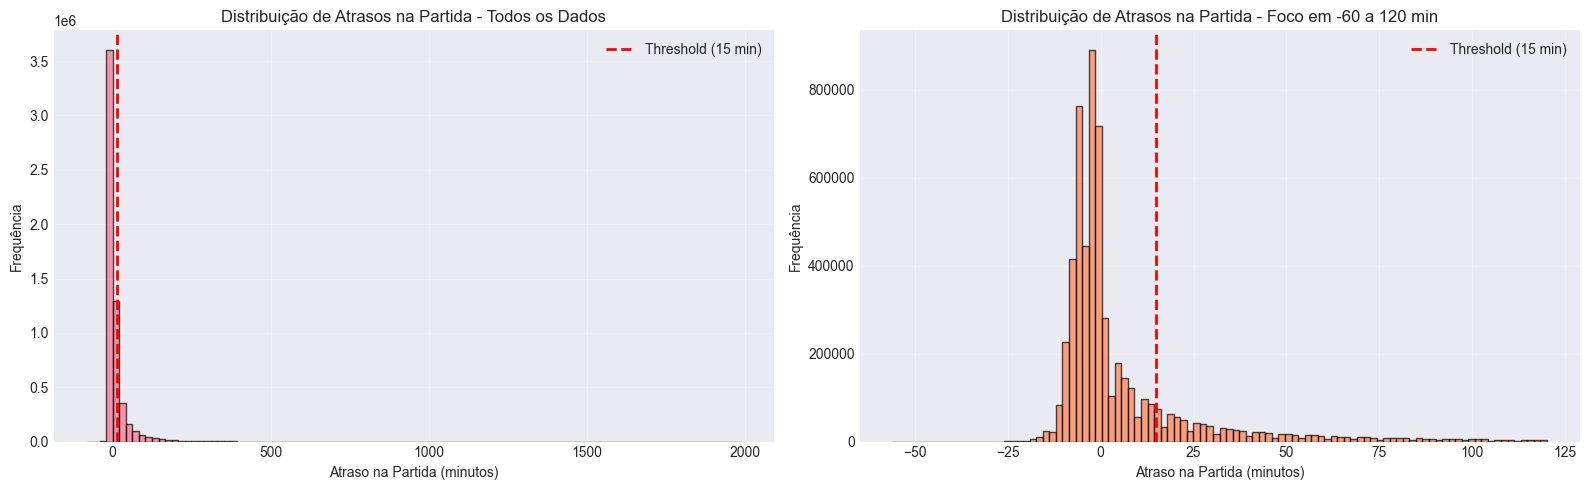

Total de voos analisados: 5,819,079
Voos com atraso > 15 min: 1,018,558


In [21]:
# Visualização 1: Histograma de atrasos na partida
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Histograma com todos os dados
axes[0].hist(df_flights['DEPARTURE_DELAY'].dropna(), bins=100, edgecolor='black', alpha=0.7)
axes[0].axvline(x=DELAY_THRESHOLD, color='red', linestyle='--', linewidth=2, label=f'Threshold ({DELAY_THRESHOLD} min)')
axes[0].set_xlabel('Atraso na Partida (minutos)')
axes[0].set_ylabel('Frequência')
axes[0].set_title('Distribuição de Atrasos na Partida - Todos os Dados')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Histograma focado em atrasos entre -60 e 120 minutos (remover outliers extremos)
delay_filtered = df_flights['DEPARTURE_DELAY'].dropna()
delay_filtered = delay_filtered[(delay_filtered >= -60) & (delay_filtered <= 120)]

axes[1].hist(delay_filtered, bins=100, edgecolor='black', alpha=0.7, color='coral')
axes[1].axvline(x=DELAY_THRESHOLD, color='red', linestyle='--', linewidth=2, label=f'Threshold ({DELAY_THRESHOLD} min)')
axes[1].set_xlabel('Atraso na Partida (minutos)')
axes[1].set_ylabel('Frequência')
axes[1].set_title('Distribuição de Atrasos na Partida - Foco em -60 a 120 min')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Total de voos analisados: {len(df_flights):,}")
print(f"Voos com atraso > {DELAY_THRESHOLD} min: {(df_flights['DEPARTURE_DELAY'] > DELAY_THRESHOLD).sum():,}")

### 7.2 Boxplots de Atrasos por Categoria

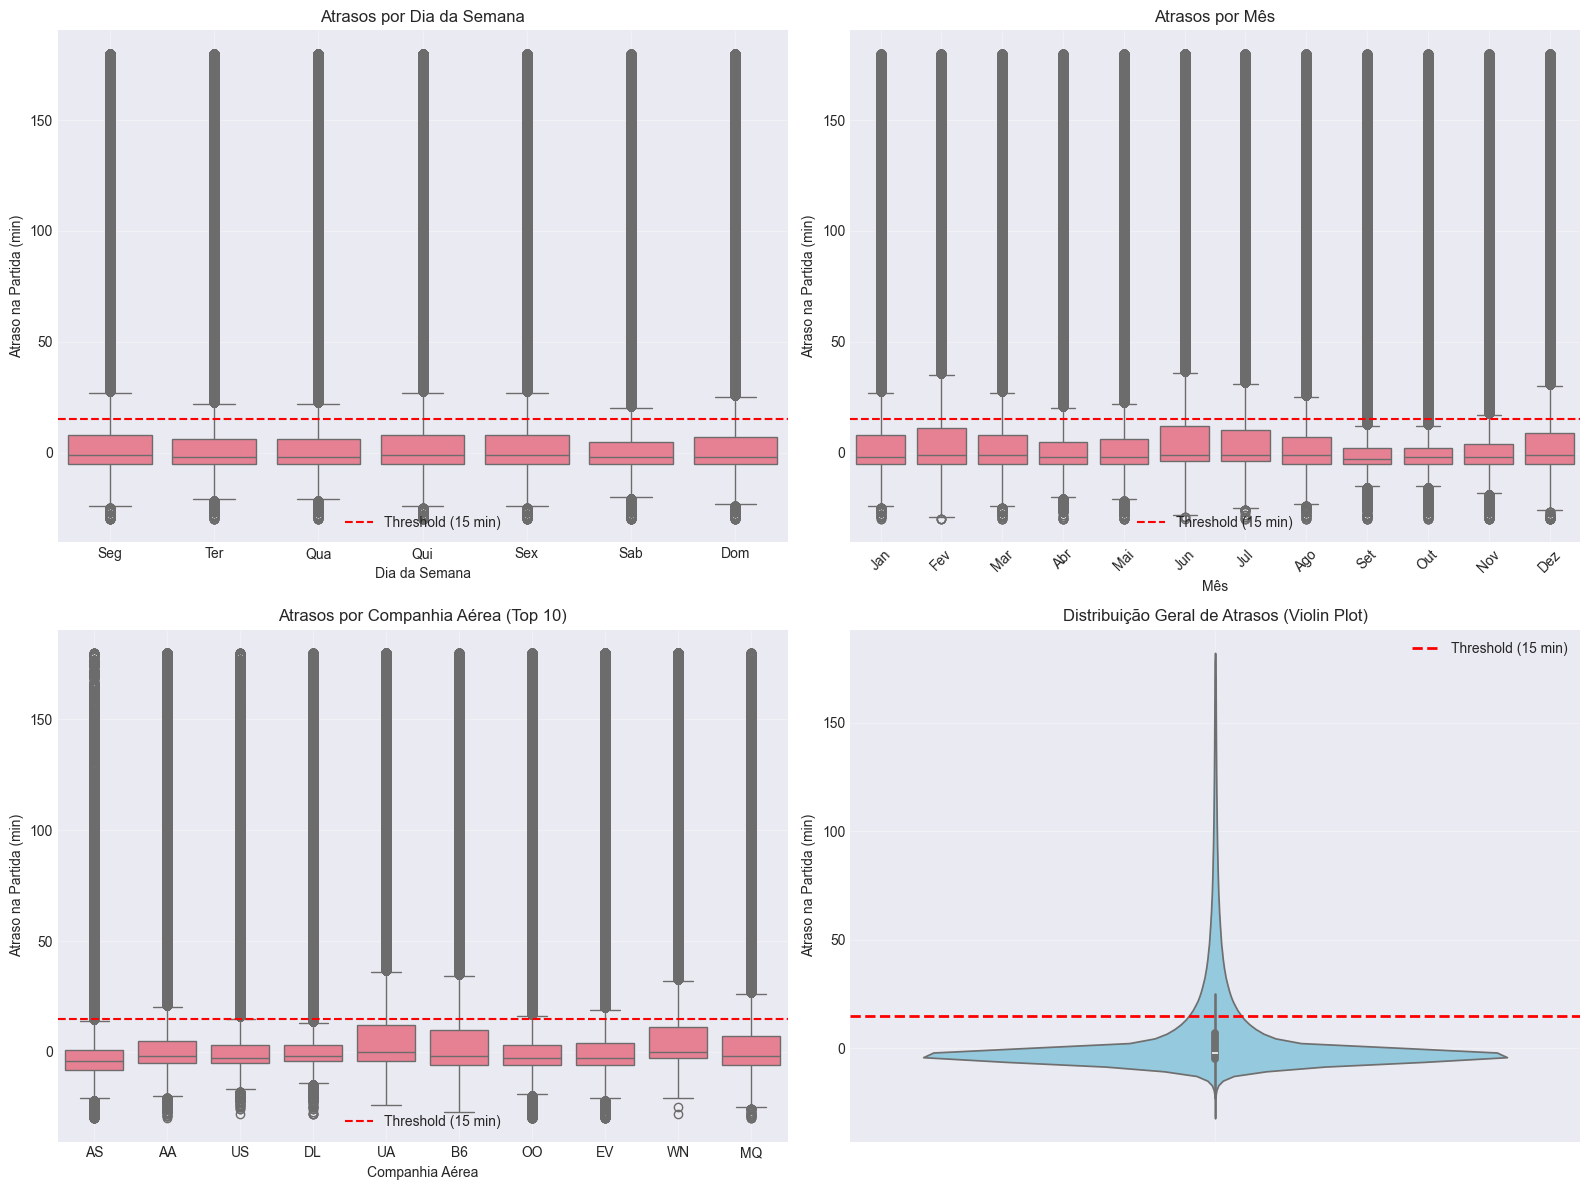

In [22]:
# Visualização 2: Boxplots de atrasos por dia da semana
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Filtrar atrasos para melhor visualização (remover outliers extremos)
df_filtered = df_flights[(df_flights['DEPARTURE_DELAY'] >= -30) & (df_flights['DEPARTURE_DELAY'] <= 180)].copy()

# Boxplot por dia da semana
weekday_names = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sab', 'Dom']
df_filtered['DAY_NAME'] = df_filtered['DAY_OF_WEEK'].map({i+1: name for i, name in enumerate(weekday_names)})
df_filtered['DAY_NAME'] = pd.Categorical(df_filtered['DAY_NAME'], categories=weekday_names, ordered=True)

sns.boxplot(data=df_filtered, x='DAY_NAME', y='DEPARTURE_DELAY', ax=axes[0, 0])
axes[0, 0].axhline(y=DELAY_THRESHOLD, color='red', linestyle='--', label=f'Threshold ({DELAY_THRESHOLD} min)')
axes[0, 0].set_xlabel('Dia da Semana')
axes[0, 0].set_ylabel('Atraso na Partida (min)')
axes[0, 0].set_title('Atrasos por Dia da Semana')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Boxplot por mês
month_names = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
df_filtered['MONTH_NAME'] = df_filtered['MONTH'].map({i+1: name for i, name in enumerate(month_names)})
df_filtered['MONTH_NAME'] = pd.Categorical(df_filtered['MONTH_NAME'], categories=month_names, ordered=True)

sns.boxplot(data=df_filtered, x='MONTH_NAME', y='DEPARTURE_DELAY', ax=axes[0, 1])
axes[0, 1].axhline(y=DELAY_THRESHOLD, color='red', linestyle='--', label=f'Threshold ({DELAY_THRESHOLD} min)')
axes[0, 1].set_xlabel('Mês')
axes[0, 1].set_ylabel('Atraso na Partida (min)')
axes[0, 1].set_title('Atrasos por Mês')
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Boxplot por companhia aérea (top 10)
top_airlines = df_flights['AIRLINE'].value_counts().head(10).index
df_top_airlines = df_filtered[df_filtered['AIRLINE'].isin(top_airlines)]

sns.boxplot(data=df_top_airlines, x='AIRLINE', y='DEPARTURE_DELAY', ax=axes[1, 0])
axes[1, 0].axhline(y=DELAY_THRESHOLD, color='red', linestyle='--', label=f'Threshold ({DELAY_THRESHOLD} min)')
axes[1, 0].set_xlabel('Companhia Aérea')
axes[1, 0].set_ylabel('Atraso na Partida (min)')
axes[1, 0].set_title('Atrasos por Companhia Aérea (Top 10)')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Violin plot: Distribuição geral
sns.violinplot(data=df_filtered, y='DEPARTURE_DELAY', ax=axes[1, 1], color='skyblue')
axes[1, 1].axhline(y=DELAY_THRESHOLD, color='red', linestyle='--', linewidth=2, label=f'Threshold ({DELAY_THRESHOLD} min)')
axes[1, 1].set_ylabel('Atraso na Partida (min)')
axes[1, 1].set_title('Distribuição Geral de Atrasos (Violin Plot)')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 7.3 Heatmaps e Análise Temporal

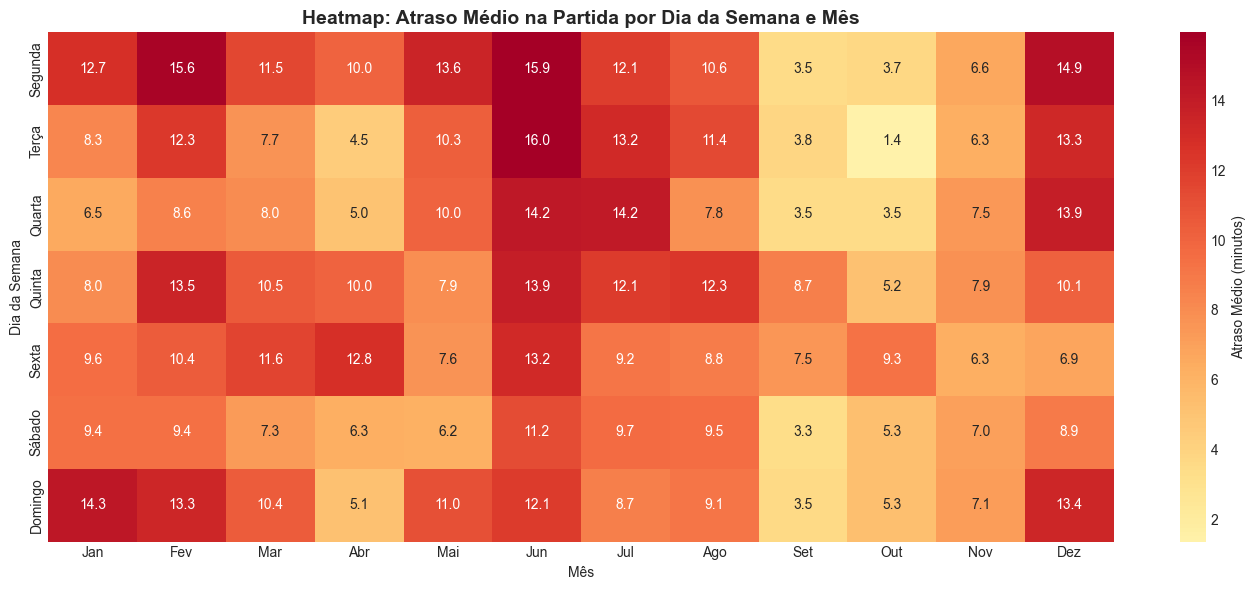

Insights:
- Maior atraso médio: 15.95 minutos
- Menor atraso médio: 1.36 minutos


In [23]:
# Visualização 3: Heatmap de atrasos médios por mês e dia da semana
# Criar pivot table
heatmap_data = df_flights.pivot_table(
    values='DEPARTURE_DELAY',
    index='DAY_OF_WEEK',
    columns='MONTH',
    aggfunc='mean'
)

# Renomear índices e colunas para nomes descritivos
heatmap_data.index = ['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo']
heatmap_data.columns = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

plt.figure(figsize=(14, 6))
sns.heatmap(heatmap_data, annot=True, fmt='.1f', cmap='RdYlGn_r', center=0, 
            cbar_kws={'label': 'Atraso Médio (minutos)'})
plt.title('Heatmap: Atraso Médio na Partida por Dia da Semana e Mês', fontsize=14, fontweight='bold')
plt.xlabel('Mês')
plt.ylabel('Dia da Semana')
plt.tight_layout()
plt.show()

print("Insights:")
print(f"- Maior atraso médio: {heatmap_data.max().max():.2f} minutos")
print(f"- Menor atraso médio: {heatmap_data.min().min():.2f} minutos")

### 7.4 Análise por Companhia Aérea

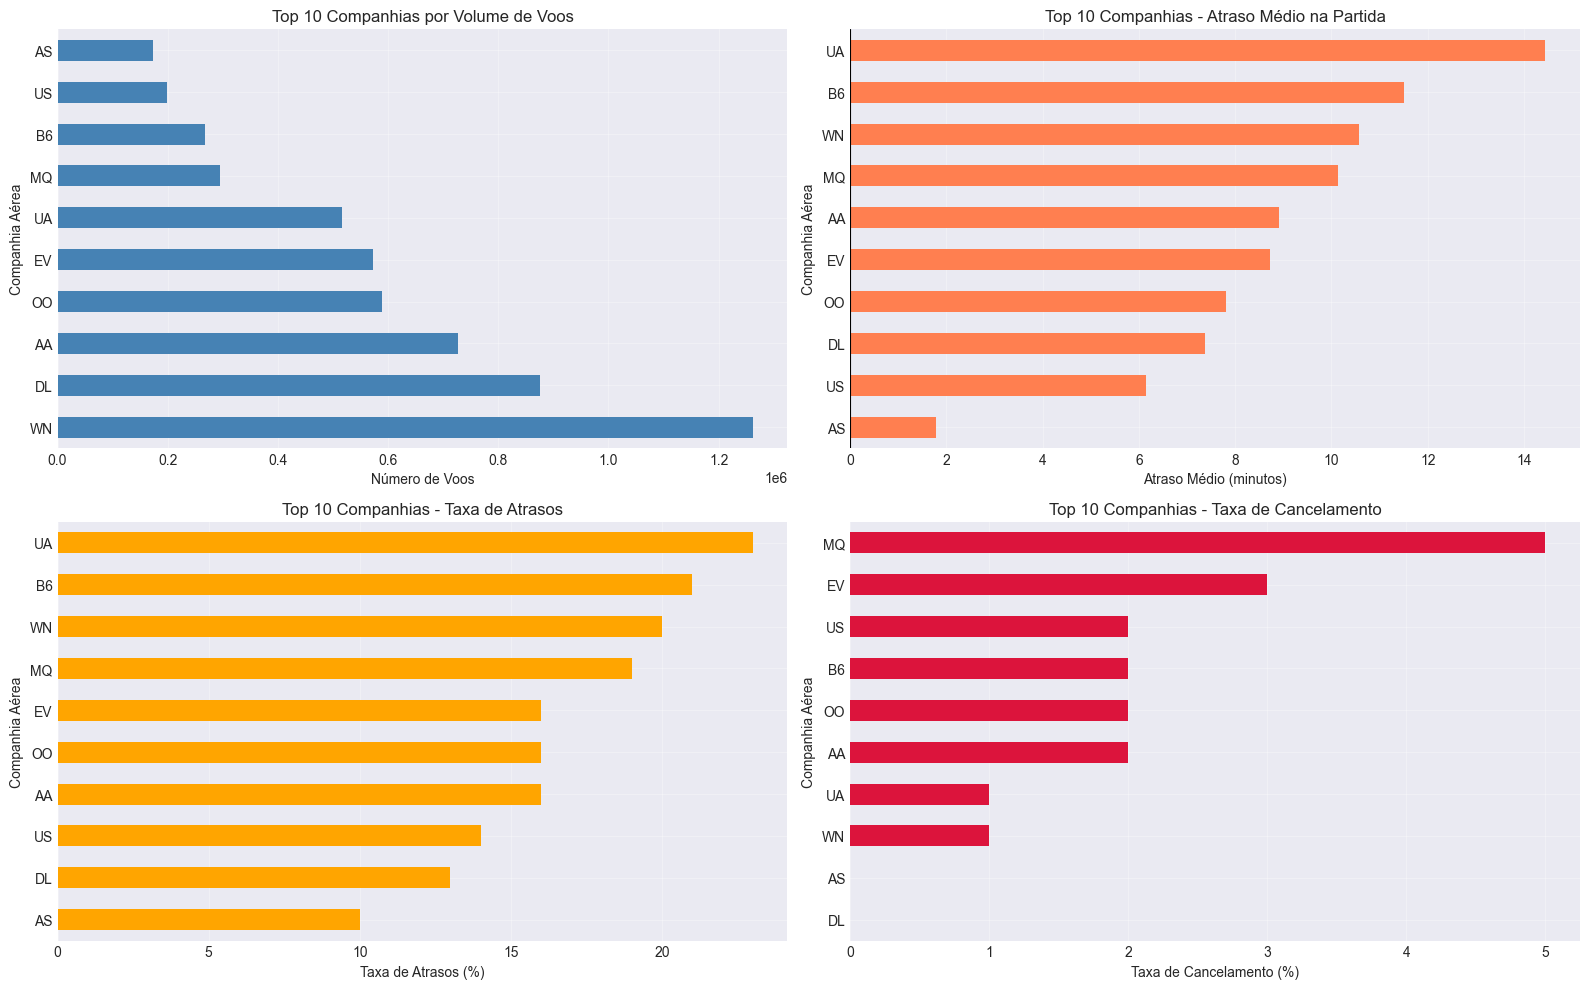


Top 5 Companhias por Volume:
         Total_Voos  Atraso_Medio  Taxa_Cancelamento  Taxa_Atraso
AIRLINE                                                          
WN          1261855         10.58               0.01         0.20
DL           875881          7.37               0.00         0.13
AA           725984          8.90               0.02         0.16
OO           588353          7.80               0.02         0.16
EV           571977          8.72               0.03         0.16


In [24]:
# Visualização 4: Análise por Companhia Aérea
airline_analysis = df_flights.groupby('AIRLINE', observed=True).agg({
    'FLIGHT_NUMBER': 'count',
    'DEPARTURE_DELAY': 'mean',
    'CANCELLED': 'mean'
}).round(2)

airline_analysis.columns = ['Total_Voos', 'Atraso_Medio', 'Taxa_Cancelamento']

# Calcular taxa de atraso diretamente
airline_analysis['Taxa_Atraso'] = df_flights.groupby('AIRLINE').apply(
    lambda x: (x['DEPARTURE_DELAY'] > DELAY_THRESHOLD).mean()
).round(2)

airline_analysis = airline_analysis.sort_values('Total_Voos', ascending=False)

# Criar subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Gráfico 1: Volume de voos por companhia
airline_analysis.head(10)['Total_Voos'].plot(kind='barh', ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Top 10 Companhias por Volume de Voos')
axes[0, 0].set_xlabel('Número de Voos')
axes[0, 0].set_ylabel('Companhia Aérea')
axes[0, 0].grid(True, alpha=0.3)

# Gráfico 2: Atraso médio por companhia
airline_analysis.head(10)['Atraso_Medio'].sort_values().plot(kind='barh', ax=axes[0, 1], color='coral')
axes[0, 1].set_title('Top 10 Companhias - Atraso Médio na Partida')
axes[0, 1].set_xlabel('Atraso Médio (minutos)')
axes[0, 1].set_ylabel('Companhia Aérea')
axes[0, 1].axvline(x=0, color='black', linestyle='-', linewidth=0.8)
axes[0, 1].grid(True, alpha=0.3)

# Gráfico 3: Taxa de atrasos por companhia
(airline_analysis.head(10)['Taxa_Atraso'] * 100).sort_values().plot(kind='barh', ax=axes[1, 0], color='orange')
axes[1, 0].set_title('Top 10 Companhias - Taxa de Atrasos')
axes[1, 0].set_xlabel('Taxa de Atrasos (%)')
axes[1, 0].set_ylabel('Companhia Aérea')
axes[1, 0].grid(True, alpha=0.3)

# Gráfico 4: Taxa de cancelamento por companhia
(airline_analysis.head(10)['Taxa_Cancelamento'] * 100).sort_values().plot(kind='barh', ax=axes[1, 1], color='crimson')
axes[1, 1].set_title('Top 10 Companhias - Taxa de Cancelamento')
axes[1, 1].set_xlabel('Taxa de Cancelamento (%)')
axes[1, 1].set_ylabel('Companhia Aérea')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nTop 5 Companhias por Volume:")
print(airline_analysis.head(5))

### 7.5 Análise de Aeroportos

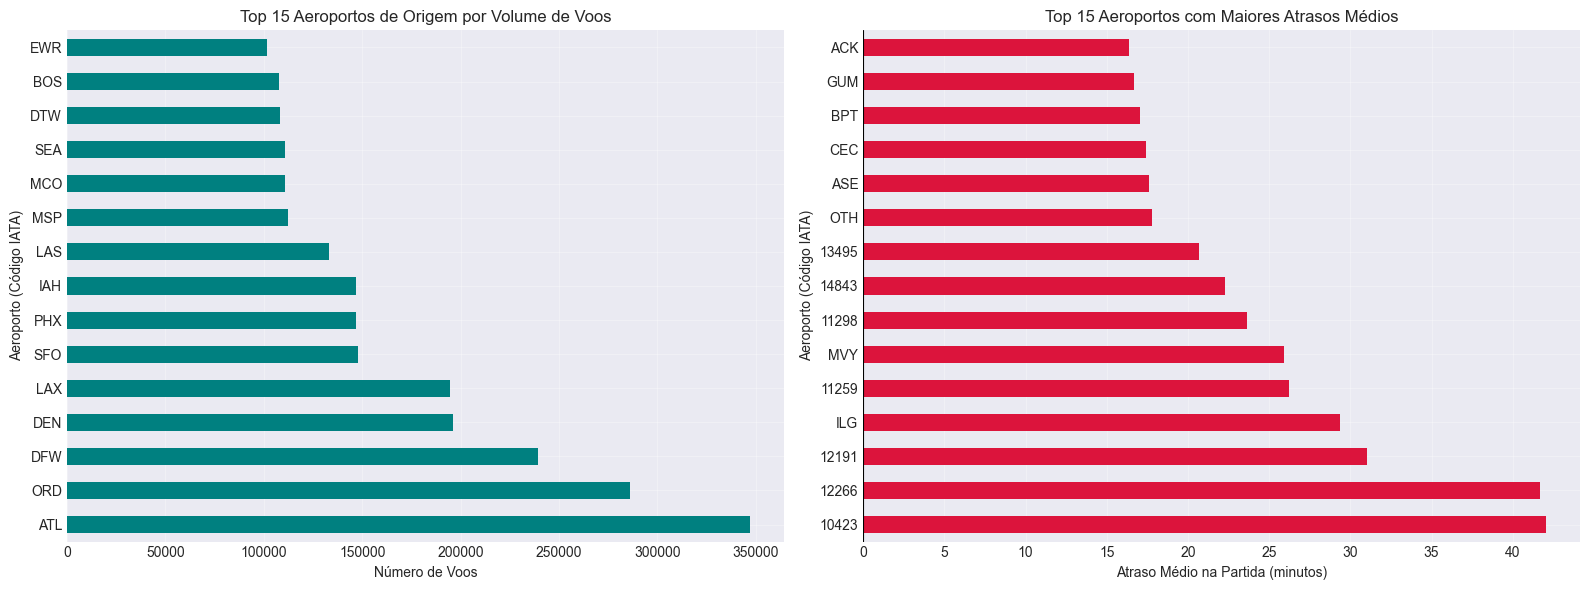


Top 10 Aeroportos Mais Movimentados:
                Total_Voos  Atraso_Medio  Taxa_Atraso
ORIGIN_AIRPORT                                       
ATL                 346836          9.34         0.17
ORD                 285884         14.15         0.23
DFW                 239551         11.53         0.21
DEN                 196055         11.84         0.22
LAX                 194673         10.67         0.20
SFO                 148008         11.19         0.20
PHX                 146815          8.67         0.18
IAH                 146622         11.58         0.20
LAS                 133181         10.95         0.21
MSP                 112117          7.26         0.14


In [25]:
# Visualização 5: Análise de Aeroportos Origem
airport_origin_analysis = df_flights.groupby('ORIGIN_AIRPORT', observed=True).agg({
    'FLIGHT_NUMBER': 'count',
    'DEPARTURE_DELAY': 'mean'
}).round(2)

airport_origin_analysis.columns = ['Total_Voos', 'Atraso_Medio']

# Calcular taxa de atraso diretamente
airport_origin_analysis['Taxa_Atraso'] = df_flights.groupby('ORIGIN_AIRPORT').apply(
    lambda x: (x['DEPARTURE_DELAY'] > DELAY_THRESHOLD).mean()
).round(2)

airport_origin_analysis = airport_origin_analysis[airport_origin_analysis['Total_Voos'] >= 100]  # Filtrar aeroportos com volume significativo
airport_origin_analysis = airport_origin_analysis.sort_values('Total_Voos', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 15 aeroportos por volume
top_airports_volume = airport_origin_analysis.head(15)
top_airports_volume['Total_Voos'].plot(kind='barh', ax=axes[0], color='teal')
axes[0].set_title('Top 15 Aeroportos de Origem por Volume de Voos')
axes[0].set_xlabel('Número de Voos')
axes[0].set_ylabel('Aeroporto (Código IATA)')
axes[0].grid(True, alpha=0.3)

# Top 15 aeroportos com maiores atrasos médios (min 100 voos)
top_airports_delay = airport_origin_analysis.sort_values('Atraso_Medio', ascending=False).head(15)
top_airports_delay['Atraso_Medio'].plot(kind='barh', ax=axes[1], color='crimson')
axes[1].set_title('Top 15 Aeroportos com Maiores Atrasos Médios')
axes[1].set_xlabel('Atraso Médio na Partida (minutos)')
axes[1].set_ylabel('Aeroporto (Código IATA)')
axes[1].axvline(x=0, color='black', linestyle='-', linewidth=0.8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nTop 10 Aeroportos Mais Movimentados:")
print(airport_origin_analysis.head(10))

### 7.6 Matriz de Correlação

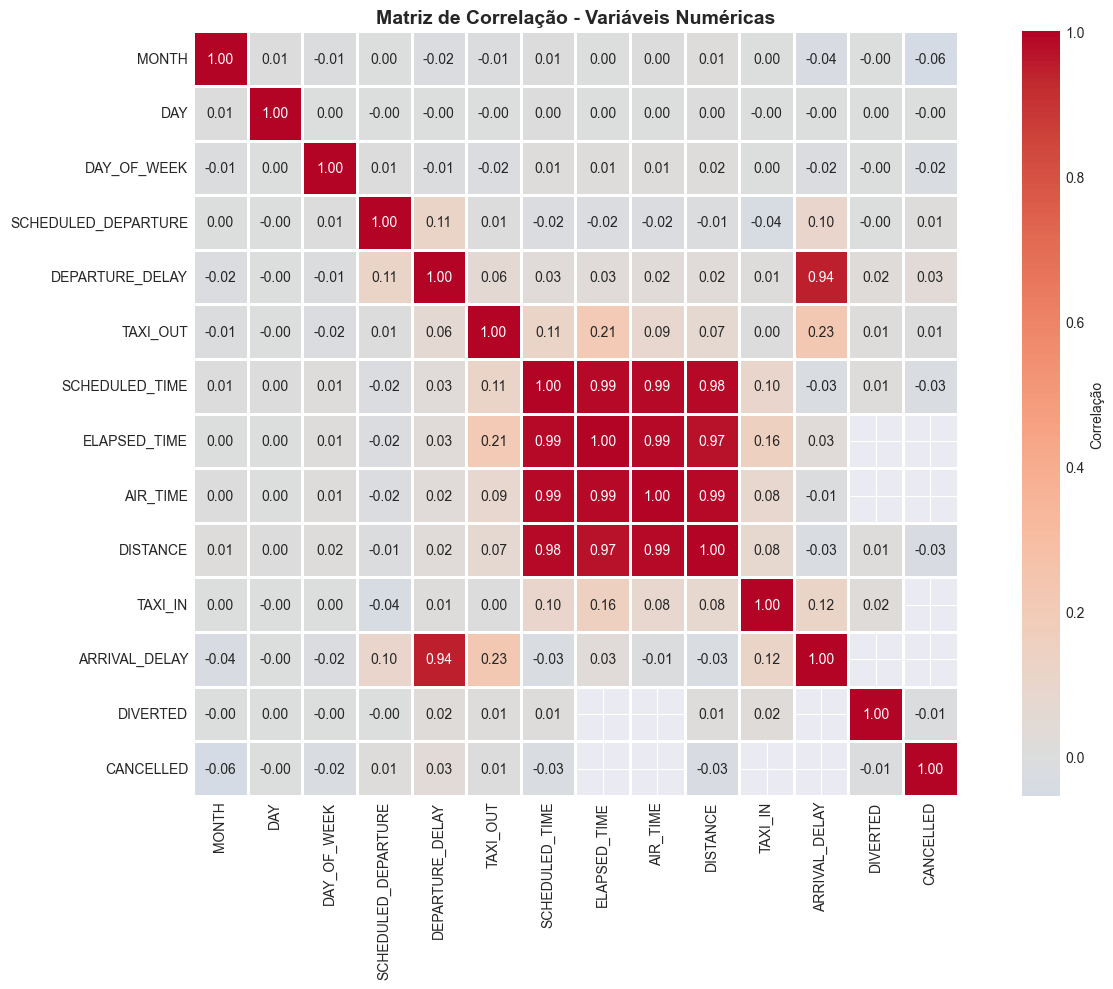


Correlações mais fortes com DEPARTURE_DELAY:
  ARRIVAL_DELAY            : +0.945
  SCHEDULED_DEPARTURE      : +0.110
  TAXI_OUT                 : +0.059
  CANCELLED                : +0.033
  ELAPSED_TIME             : +0.031
  SCHEDULED_TIME           : +0.028
  DISTANCE                 : +0.024
  AIR_TIME                 : +0.023
  DIVERTED                 : +0.023
  TAXI_IN                  : +0.013
  DAY                      : -0.000
  DAY_OF_WEEK              : -0.012
  MONTH                    : -0.022


In [26]:
# Visualização 6: Matriz de Correlação
# Selecionar variáveis numéricas relevantes
correlation_vars = [
    'MONTH', 'DAY', 'DAY_OF_WEEK',
    'SCHEDULED_DEPARTURE', 'DEPARTURE_DELAY', 'TAXI_OUT',
    'SCHEDULED_TIME', 'ELAPSED_TIME', 'AIR_TIME', 'DISTANCE',
    'TAXI_IN', 'ARRIVAL_DELAY', 'DIVERTED', 'CANCELLED'
]

# Filtrar apenas as colunas que existem no dataset
available_vars = [var for var in correlation_vars if var in df_flights.columns]
correlation_matrix = df_flights[available_vars].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=1, cbar_kws={'label': 'Correlação'})
plt.title('Matriz de Correlação - Variáveis Numéricas', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Correlações mais fortes com DEPARTURE_DELAY
print("\nCorrelações mais fortes com DEPARTURE_DELAY:")
delay_corr = correlation_matrix['DEPARTURE_DELAY'].sort_values(ascending=False)
for var, corr in delay_corr.items():
    if var != 'DEPARTURE_DELAY':
        print(f"  {var:25s}: {corr:+.3f}")

### 7.7 Análise de Distância vs Atraso

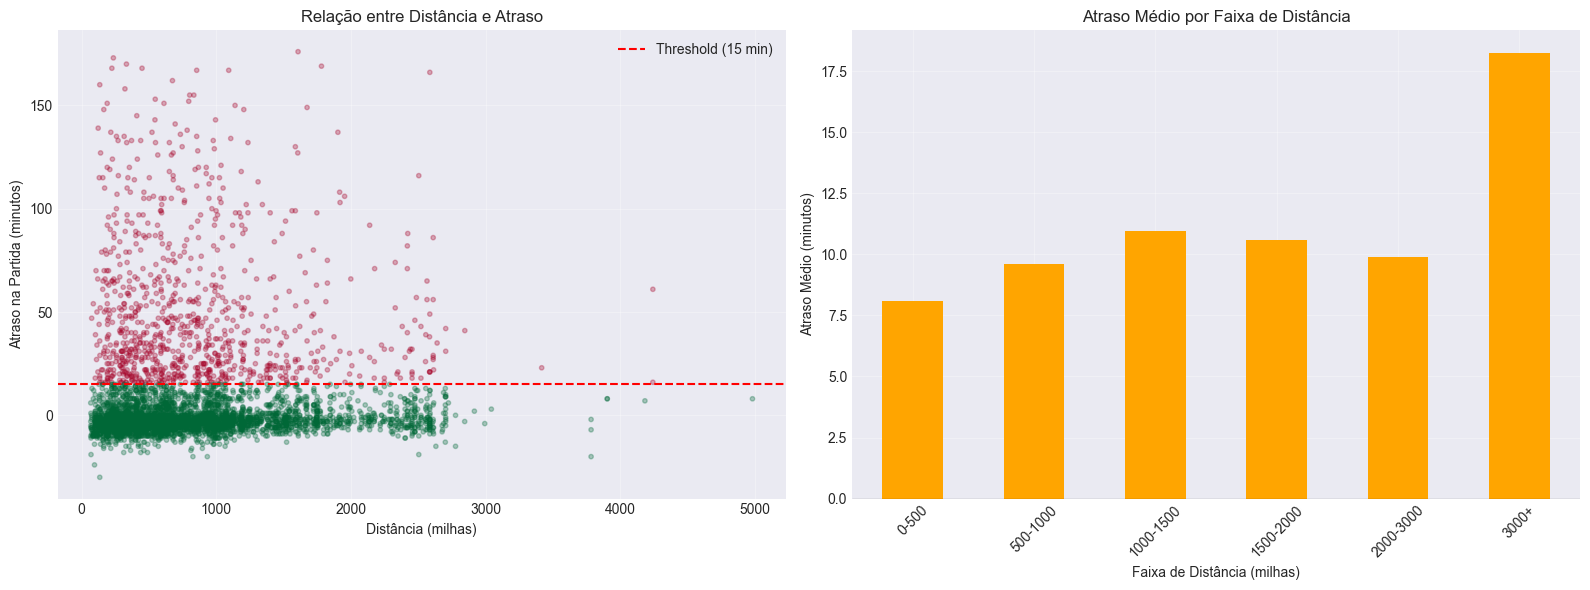


Atraso médio por faixa de distância:
  0-500          : +8.11 minutos
  500-1000       : +9.63 minutos
  1000-1500      : +10.96 minutos
  1500-2000      : +10.58 minutos
  2000-3000      : +9.89 minutos
  3000+          : +18.26 minutos


In [27]:
# Visualização 7: Relação entre Distância e Atraso
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter plot com amostra (para não sobrecarregar)
sample_scatter = df_flights.sample(n=min(5000, len(df_flights)), random_state=RANDOM_STATE)
sample_scatter = sample_scatter[(sample_scatter['DEPARTURE_DELAY'] >= -30) & (sample_scatter['DEPARTURE_DELAY'] <= 180)]

# Criar coluna temporária IS_DELAYED para visualização
sample_scatter_with_flag = sample_scatter.copy()
sample_scatter_with_flag['IS_DELAYED_TEMP'] = (sample_scatter_with_flag['DEPARTURE_DELAY'] > DELAY_THRESHOLD).astype(int)

axes[0].scatter(sample_scatter_with_flag['DISTANCE'], sample_scatter_with_flag['DEPARTURE_DELAY'], 
                alpha=0.3, s=10, c=sample_scatter_with_flag['IS_DELAYED_TEMP'], cmap='RdYlGn_r')
axes[0].set_xlabel('Distância (milhas)')
axes[0].set_ylabel('Atraso na Partida (minutos)')
axes[0].set_title('Relação entre Distância e Atraso')
axes[0].axhline(y=DELAY_THRESHOLD, color='red', linestyle='--', label=f'Threshold ({DELAY_THRESHOLD} min)')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Atraso médio por faixa de distância
df_flights_temp = df_flights.copy()
df_flights_temp['DISTANCE_BIN'] = pd.cut(df_flights_temp['DISTANCE'], 
                                      bins=[0, 500, 1000, 1500, 2000, 3000, 5000],
                                      labels=['0-500', '500-1000', '1000-1500', '1500-2000', '2000-3000', '3000+'])

delay_by_distance = df_flights_temp.groupby('DISTANCE_BIN', observed=True)['DEPARTURE_DELAY'].mean()
delay_by_distance.plot(kind='bar', ax=axes[1], color='orange')
axes[1].set_xlabel('Faixa de Distância (milhas)')
axes[1].set_ylabel('Atraso Médio (minutos)')
axes[1].set_title('Atraso Médio por Faixa de Distância')
axes[1].axhline(y=0, color='black', linestyle='-', linewidth=0.8)
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nAtraso médio por faixa de distância:")
for dist_bin, avg_delay in delay_by_distance.items():
    print(f"  {dist_bin:15s}: {avg_delay:+.2f} minutos")

---
## 8. Conclusões e Insights <a id='8-conclusoes'></a>

### 8.1 Principais Descobertas

In [28]:
# Resumo final dos insights
print("="*80)
print("PRINCIPAIS DESCOBERTAS DA ANALISE EXPLORATORIA")
print("="*80)

# 1. Distribuição de atrasos (calcular diretamente sem usar IS_DELAYED)
delayed_count = (df_flights['DEPARTURE_DELAY'] > DELAY_THRESHOLD).sum()
delayed_pct = (delayed_count / len(df_flights)) * 100
print(f"\n1. DISTRIBUICAO DE ATRASOS:")
print(f"   - Taxa de voos atrasados (>{DELAY_THRESHOLD} min): {delayed_pct:.2f}%")
print(f"   - Atraso médio na partida: {df_flights['DEPARTURE_DELAY'].mean():.2f} minutos")
print(f"   - Atraso médio na chegada: {df_flights['ARRIVAL_DELAY'].mean():.2f} minutos")

# 2. Padrões temporais
print(f"\n2. PADROES TEMPORAIS:")
monthly_avg = df_flights.groupby('MONTH', observed=True)['DEPARTURE_DELAY'].mean()
worst_month = monthly_avg.idxmax()
best_month = monthly_avg.idxmin()
month_names = ['', 'Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
print(f"   - Pior mês: {month_names[worst_month]} (atraso médio: {monthly_avg[worst_month]:.2f} min)")
print(f"   - Melhor mês: {month_names[best_month]} (atraso médio: {monthly_avg[best_month]:.2f} min)")

weekday_avg = df_flights.groupby('DAY_OF_WEEK', observed=True)['DEPARTURE_DELAY'].mean()
worst_day = weekday_avg.idxmax()
best_day = weekday_avg.idxmin()
weekday_names = ['', 'Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo']
print(f"   - Pior dia da semana: {weekday_names[worst_day]} (atraso médio: {weekday_avg[worst_day]:.2f} min)")
print(f"   - Melhor dia da semana: {weekday_names[best_day]} (atraso médio: {weekday_avg[best_day]:.2f} min)")

# 3. Companhias aéreas
airline_stats = df_flights.groupby('AIRLINE').agg({
    'DEPARTURE_DELAY': 'mean',
    'FLIGHT_NUMBER': 'count'
})
airline_stats = airline_stats[airline_stats['FLIGHT_NUMBER'] >= 100]  # Min 100 voos
worst_airline = airline_stats['DEPARTURE_DELAY'].idxmax()
best_airline = airline_stats['DEPARTURE_DELAY'].idxmin()

print(f"\n3. COMPANHIAS AEREAS:")
print(f"   - Pior desempenho: {worst_airline} (atraso médio: {airline_stats.loc[worst_airline, 'DEPARTURE_DELAY']:.2f} min)")
print(f"   - Melhor desempenho: {best_airline} (atraso médio: {airline_stats.loc[best_airline, 'DEPARTURE_DELAY']:.2f} min)")

# 4. Aeroportos
airport_stats = df_flights.groupby('ORIGIN_AIRPORT').agg({
    'DEPARTURE_DELAY': 'mean',
    'FLIGHT_NUMBER': 'count'
})
airport_stats = airport_stats[airport_stats['FLIGHT_NUMBER'] >= 100]  # Min 100 voos
worst_airport = airport_stats['DEPARTURE_DELAY'].idxmax()
busiest_airport = airport_stats['FLIGHT_NUMBER'].idxmax()

print(f"\n4. AEROPORTOS:")
print(f"   - Mais movimentado: {busiest_airport} ({airport_stats.loc[busiest_airport, 'FLIGHT_NUMBER']:,} voos)")
print(f"   - Maior atraso médio: {worst_airport} (atraso médio: {airport_stats.loc[worst_airport, 'DEPARTURE_DELAY']:.2f} min)")

# 5. Cancelamentos
cancelled_pct = (df_flights['CANCELLED'].sum() / len(df_flights)) * 100
diverted_pct = (df_flights['DIVERTED'].sum() / len(df_flights)) * 100

print(f"\n5. CANCELAMENTOS E DESVIOS:")
print(f"   - Taxa de cancelamento: {cancelled_pct:.2f}%")
print(f"   - Taxa de desvios: {diverted_pct:.2f}%")

# 6. Valores ausentes
missing_summary = df_flights.isnull().sum()
missing_summary = missing_summary[missing_summary > 0]
if len(missing_summary) > 0:
    print(f"\n6. VALORES AUSENTES:")
    print(f"   - Total de colunas com missing values: {len(missing_summary)}")
    print(f"   - Coluna com mais missing: {missing_summary.idxmax()} ({missing_summary.max():,} valores)")
else:
    print(f"\n6. VALORES AUSENTES:")
    print(f"   - Nenhum valor ausente encontrado!")

print("\n" + "="*80)

PRINCIPAIS DESCOBERTAS DA ANALISE EXPLORATORIA

1. DISTRIBUICAO DE ATRASOS:
   - Taxa de voos atrasados (>15 min): 17.50%
   - Atraso médio na partida: 9.37 minutos
   - Atraso médio na chegada: 4.41 minutos

2. PADROES TEMPORAIS:
   - Pior mês: Jun (atraso médio: 13.99 min)
   - Melhor mês: Set (atraso médio: 4.82 min)
   - Pior dia da semana: Segunda (atraso médio: 10.87 min)
   - Melhor dia da semana: Sábado (atraso médio: 7.83 min)

3. COMPANHIAS AEREAS:
   - Pior desempenho: NK (atraso médio: 15.94 min)
   - Melhor desempenho: HA (atraso médio: 0.49 min)

4. AEROPORTOS:
   - Mais movimentado: ATL (346,836 voos)
   - Maior atraso médio: 10423 (atraso médio: 42.04 min)

5. CANCELAMENTOS E DESVIOS:
   - Taxa de cancelamento: 1.54%
   - Taxa de desvios: 0.26%

6. VALORES AUSENTES:
   - Total de colunas com missing values: 19
   - Coluna com mais missing: CANCELLATION_REASON (5,729,195 valores)



### 8.2 Próximos Passos

Com base na análise exploratória realizada, os próximos passos do projeto são:

**1. Tratamento de Dados**
- Definir estratégias para valores ausentes
- Criar features derivadas (período do dia, fim de semana, estações)
- Preparar dados para modelagem

**2. Modelagem Supervisionada**
- Classificação: Prever se voo vai atrasar (IS_DELAYED)
- Regressão: Prever quanto tempo vai atrasar (DELAY_MINUTES)
- Algoritmos a testar: Regressão Logística, Random Forest, XGBoost

**3. Modelagem Não Supervisionada**
- Clustering de aeroportos/rotas/companhias
- PCA para redução dimensional e visualização

**4. Análise Final**
- Comparação de modelos
- Feature importance
- Insights acionáveis para o negócio